# Quasi-resonant amplification: does a trapped, near-stationary large-scale wave explain persistence?

**Motivation.** Two prior notebooks tested related-sounding but genuinely different
ideas and both came back null: `CA_ridging_persistence_drivers_waf.ipynb` tested
*discrete reinforcement pulses* (does a long episode get re-forced by separate
wave-breaking events?), and `CA_2026_dynamic_tropopause_diagnosis.ipynb` tested
*whole-field phase speed* (does the dynamic-tropopause wave pattern move slower during
March?) -- finding the *same* phase speed before and during the record episode, which
retracted the "textbook blocking, wave stalls" reading. Neither tests the specific
mechanism in quasi-resonant amplification (QRA) theory (Petoukhov et al. 2013; Coumou
et al. 2014): a particular large-scale zonal wave gets trapped by a waveguide
configuration (a double jet, or a meridionally confined guide) and amplifies in place
with near-zero *wave-specific* phase speed, which a whole-field cross-correlation
(mixing all spatial scales together) is not built to isolate.

**Two real limitations, stated up front, that shape what this notebook can and can't
claim:**
1. **This project's only upstream field is regional, not global.** QRA theory is
   formally about *global* zonal wavenumbers (integer harmonics around a full latitude
   circle, classically wavenumber 6-8). `upstream_pacific_<year>.nc` only covers a
   140-250E Pacific-North America sector (~110 degrees of longitude) -- about 30% of a
   full latitude circle. A true global-wavenumber decomposition isn't possible with
   this project's data; doing one would require fetching full-longitude Z300 (cost not
   estimated here, but by analogy with the Pacific-sector fetch, non-trivial). This
   notebook instead fits a **single dominant large-scale harmonic** (one full
   wave-cycle spanning the available 110-degree sector) to the day's height field --
   an honestly-labeled proxy for "is there a coherent large-scale ridge-trough wave in
   this sector, and is it amplified and stationary," not a genuine wavenumber-6-to-8
   attribution. Flagged explicitly to avoid false precision.
2. **Fixed-pressure Z300, not the dynamic tropopause.** Matches the WAF and jet-speed
   notebooks' convention (and the QRA literature's own typical choice of a fixed upper-
   level field) and -- unlike the DT notebook -- `upstream_pacific_<year>.nc` exists for
   the full 1990-2025 record, so this gets a real statistical test instead of the DT
   notebook's unavoidable n=1 (one season).

**Two tests:** (1) does this sector's dominant large-scale wave's amplitude and
quasi-stationarity (low |phase speed|) predict episode duration across the full
record, and (2) does the background jet show a waveguide-favorable double-jet
structure during long episodes, specifically March. No new fetch -- reuses
`upstream_pacific_<year>.nc`, already in hand.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr, percentileofscore
from scipy.signal import argrelmax
from scipy.ndimage import gaussian_filter1d
import sys

import os
os.environ.setdefault('PROJ_DATA', str(Path(sys.prefix) / 'share' / 'proj'))

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
FIT_YEARS = list(range(1990, 2026))
YEAR_2026 = 2026
ALL_YEARS = FIT_YEARS + [YEAR_2026]
THRESHOLD_SD = 1
VARS = [('z500', '500 hPa height (ridging)'), ('t700', '700 hPa temperature (warm)')]
COLOR = {'500 hPa height (ridging)': '#2a78d6', '700 hPa temperature (warm)': '#eb6834'}
N_BOOT = 2000
rng = np.random.default_rng(42)

CLIM_WINDOW = 5
MIN_DURATION = 5
MAX_GAP = 1
SIGN = 1

R_EARTH = 6.371e6   # m
WAVEGUIDE_LAT = slice(55, 35)   # meridional averaging band for the single-harmonic fit
JET_LON = slice(150, 246)       # NW-Pacific-to-CA swath for the jet meridional profile, matches
                                 # CA_ridging_persistence_drivers_waf.ipynb's PATH_LON convention


## 1. Load the full-record Method A event table

Same `ca_z500_t700_events_1990-2025_detrended_mindur5.csv` used throughout this
mechanism thread.

In [2]:
events = pd.read_csv(DATA_DIR / 'ca_z500_t700_events_1990-2025_detrended_mindur5.csv',
                     parse_dates=['start_date', 'end_date'])
events['start_date'] = events.start_date.dt.date
events['end_date'] = events.end_date.dt.date
events = events[events.threshold_sd == THRESHOLD_SD].reset_index(drop=True)

print(f'{len(events)} events at >= {THRESHOLD_SD} sigma, by variable:')
print(events.groupby('variable').size())


95 events at >= 1 sigma, by variable:
variable
500 hPa height (ridging)      48
700 hPa temperature (warm)    47
dtype: int64


## 2. Per-year single-harmonic wave fit and jet meridional profile

For each day: (a) meridionally average Z300 over the waveguide band (35-55N), remove
that day's own zonal mean, and fit a single cosine+sine harmonic (one full cycle
across the available 110-degree sector) by direct projection (closed-form Fourier
coefficients, not an iterative fit) -- giving amplitude and phase per day; (b)
longitude-average U300 over the NW-Pacific-to-CA swath to get the day's meridional jet
profile, for the waveguide/double-jet check in Section 5.

In [3]:
def compute_wave_and_jet_daily(year):
    ds = xr.open_dataset(DATA_DIR / f'upstream_pacific_{year}.nc', engine='netcdf4')
    ds = ds[['z300', 'u300']].sel(time=ds.time.dt.month.isin([1, 2, 3, 4]))

    lat = ds.latitude.values
    lon = ds.longitude.values
    time_index = pd.to_datetime(ds.time.values)

    wg_lat_idx = (lat <= WAVEGUIDE_LAT.start) & (lat >= WAVEGUIDE_LAT.stop)
    z_wg = ds.z300.values[:, wg_lat_idx, :].mean(axis=1)   # (time, lon)

    S = lon.max() - lon.min()
    theta = 2 * np.pi * (lon - lon.min()) / S
    cos_t, sin_t = np.cos(theta), np.sin(theta)

    y = z_wg - z_wg.mean(axis=1, keepdims=True)
    A = (2.0 / len(lon)) * (y @ cos_t)
    B = (2.0 / len(lon)) * (y @ sin_t)
    amplitude = np.sqrt(A**2 + B**2)
    phase = np.arctan2(B, A)

    wave_mid_lat = (WAVEGUIDE_LAT.start + WAVEGUIDE_LAT.stop) / 2
    deg_per_day = np.full(len(time_index), np.nan)
    unwrapped = np.unwrap(phase)
    dphi = np.diff(unwrapped, prepend=unwrapped[0])
    deg_per_day[1:] = np.rad2deg(dphi[1:]) * (S / 360.0)
    m_per_deg = (np.pi / 180.0) * R_EARTH * np.cos(np.deg2rad(wave_mid_lat))
    phase_speed = deg_per_day * m_per_deg / 86400.0   # m/s

    jet_lon_idx = (lon >= JET_LON.start) & (lon <= JET_LON.stop)
    jet_profile = ds.u300.values[:, :, jet_lon_idx].mean(axis=2)   # (time, lat)
    jet_profile_smooth = gaussian_filter1d(jet_profile, sigma=2.0, axis=1)

    secondary_ratio = np.zeros(len(time_index))
    for i in range(len(time_index)):
        prof = jet_profile_smooth[i]
        peaks = argrelmax(prof, order=3)[0]
        if len(peaks) < 2:
            continue
        heights = np.sort(prof[peaks])[::-1]
        if heights[0] > 0:
            secondary_ratio[i] = max(0.0, heights[1] / heights[0])

    return pd.DataFrame({'amplitude': amplitude, 'phase_speed': phase_speed,
                          'jet_secondary_ratio': secondary_ratio}, index=time_index)


daily_frames = [compute_wave_and_jet_daily(y) for y in ALL_YEARS]
daily_wave = pd.concat(daily_frames).sort_index()
print(f'{len(daily_wave)} days processed, {ALL_YEARS[0]}-{ALL_YEARS[-1]}')
print(daily_wave.describe())


4449 days processed, 1990-2026
         amplitude  phase_speed  jet_secondary_ratio
count  4449.000000  4412.000000          4449.000000
mean    193.779641     0.714687             0.506208
std      93.808785     8.455297             0.349621
min       0.955603   -50.039776             0.000000
25%     120.939758    -2.495979             0.185190
50%     188.252469     0.676110             0.544506
75%     259.506145     3.712895             0.834337
max     487.800236    49.371740             0.999983


## 3. Compute the three predictors for every fit-period event

- `qra_amplitude_mean`: mean single-harmonic amplitude over the event's own window
- `qra_phase_speed_abs_mean`: mean |phase speed| over the window -- low values mean the
  sector's dominant wave was quasi-stationary during the event
- `jet_secondary_ratio_mean`: mean double-jet ratio over the window (0 = single jet
  core, closer to 1 = two comparably strong jet cores -- the QRA waveguide
  precondition)

In [4]:
def window_mean(series, start, end):
    window = series.loc[str(start):str(end)]
    return float(window.mean()) if len(window) else np.nan


def window_mean_abs(series, start, end):
    window = series.loc[str(start):str(end)]
    return float(window.abs().mean()) if len(window) else np.nan


rows = []
for row in events.itertuples():
    rows.append({
        'qra_amplitude_mean': window_mean(daily_wave.amplitude, row.start_date, row.end_date),
        'qra_phase_speed_abs_mean': window_mean_abs(daily_wave.phase_speed, row.start_date, row.end_date),
        'jet_secondary_ratio_mean': window_mean(daily_wave.jet_secondary_ratio, row.start_date, row.end_date),
    })
qra_predictors = pd.DataFrame(rows)
events_full = pd.concat([events.reset_index(drop=True), qra_predictors], axis=1)
events_full[['variable', 'start_date', 'duration_days'] + list(qra_predictors.columns)].head(5)


,variable,start_date,duration_days,qra_amplitude_mean,qra_phase_speed_abs_mean,jet_secondary_ratio_mean
0,500 hPa height (ridging),1990-02-21,5,213.704782,4.903717,0.788452
1,500 hPa height (ridging),1990-03-19,5,177.419393,2.740603,0.290496
2,500 hPa height (ridging),1990-04-10,6,84.434734,10.378691,0.600797
3,500 hPa height (ridging),1992-02-21,8,245.213111,2.618105,0.273806
4,500 hPa height (ridging),1992-04-24,6,75.228313,11.739303,0.903106


## 4. Duration vs. each QRA-related predictor, full record

If QRA explains persistence, expect a **positive** rho for amplitude (more amplified
-> longer) and a **negative** rho for |phase speed| (more stationary -> longer).

In [5]:
def bootstrap_spearman_ci(x, y, n_boot=N_BOOT, ci=90, rng=rng):
    n = len(x)
    boot = np.empty(n_boot)
    idx_pool = np.arange(n)
    for b in range(n_boot):
        idx = rng.choice(idx_pool, size=n, replace=True)
        boot[b] = spearmanr(x[idx], y[idx]).statistic
    lo, hi = np.percentile(boot, [(100 - ci) / 2, 100 - (100 - ci) / 2])
    return lo, hi


PREDICTORS = ['qra_amplitude_mean', 'qra_phase_speed_abs_mean', 'jet_secondary_ratio_mean']
PRED_LABELS = {
    'qra_amplitude_mean': 'dominant large-scale wave amplitude (m)',
    'qra_phase_speed_abs_mean': '|phase speed| of that wave (m/s)',
    'jet_secondary_ratio_mean': 'jet double-core ratio (waveguide proxy)',
}

results = []
for col, label in VARS:
    sub = events_full[events_full.variable == label]
    for pred in PREDICTORS:
        valid = sub[['duration_days', pred]].dropna()
        x, y = valid.duration_days.values, valid[pred].values
        rho, p = spearmanr(x, y)
        lo, hi = bootstrap_spearman_ci(x, y)
        results.append({'variable': label, 'predictor': pred, 'n': len(valid),
                         'rho': rho, 'p_spearman': p, 'ci_lo': lo, 'ci_hi': hi})

results_df = pd.DataFrame(results)
results_df['predictor_label'] = results_df.predictor.map(PRED_LABELS)
pd.set_option('display.width', 120)
results_df[['variable', 'predictor_label', 'n', 'rho', 'p_spearman', 'ci_lo', 'ci_hi']]


,variable,predictor_label,n,rho,p_spearman,ci_lo,ci_hi
0,500 hPa height (ridging),dominant large-scale wave amplitude (m),48,0.111631,0.450019,-0.132441,0.346631
1,500 hPa height (ridging),|phase speed| of that wave (m/s),48,-0.116215,0.431511,-0.352349,0.126092
2,500 hPa height (ridging),jet double-core ratio (waveguide proxy),48,-0.335509,0.019742,-0.558988,-0.111221
3,700 hPa temperature (warm),dominant large-scale wave amplitude (m),47,0.319703,0.028481,0.124248,0.496171
4,700 hPa temperature (warm),|phase speed| of that wave (m/s),47,-0.184989,0.213188,-0.386696,0.050704
5,700 hPa temperature (warm),jet double-core ratio (waveguide proxy),47,-0.234201,0.113082,-0.448971,0.006998


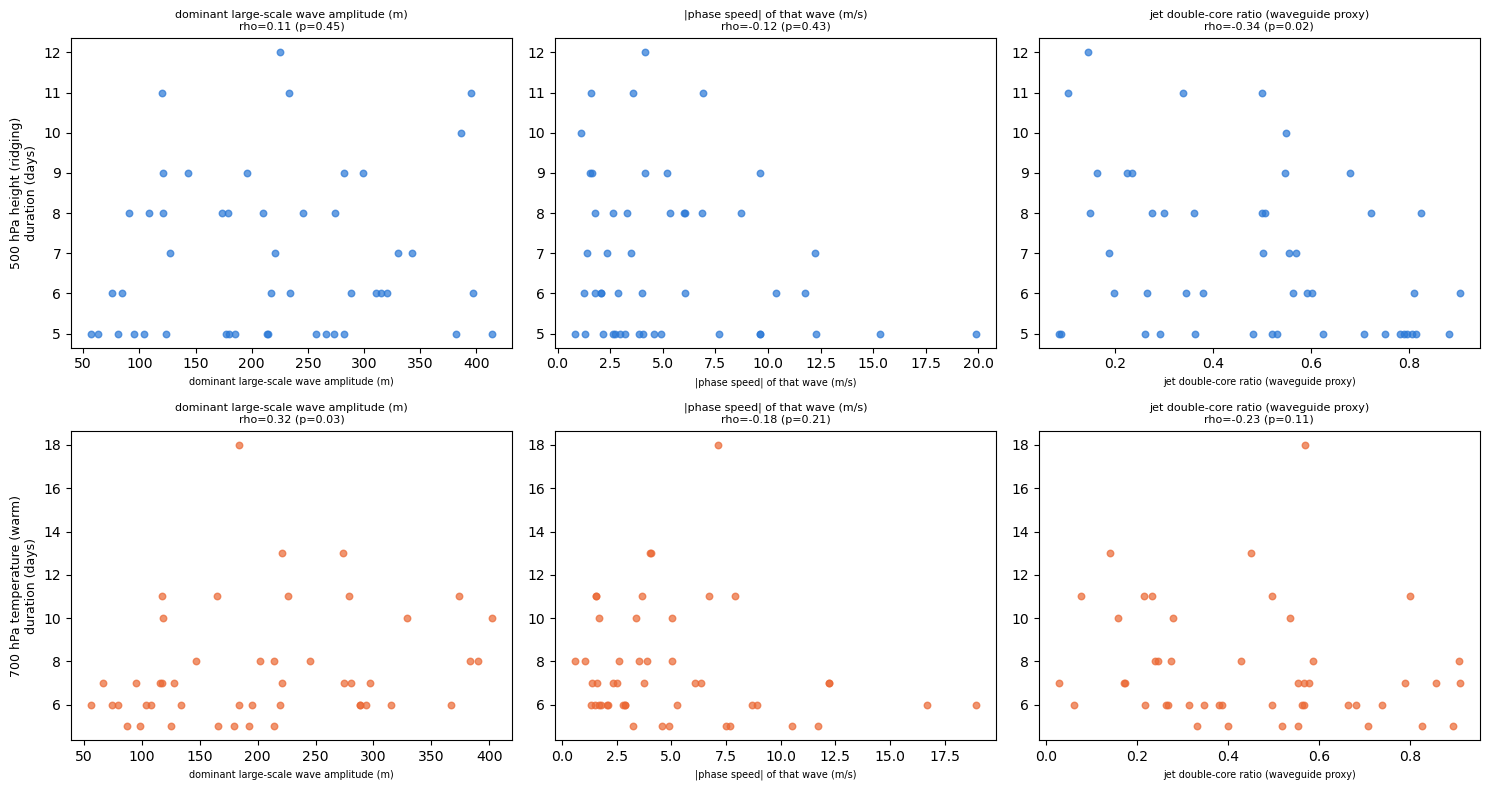

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, (col, label) in enumerate(VARS):
    sub = events_full[events_full.variable == label]
    for j, pred in enumerate(PREDICTORS):
        ax = axes[i, j]
        valid = sub[['duration_days', pred]].dropna()
        ax.scatter(valid[pred], valid.duration_days, s=22, alpha=0.7, color=COLOR[label])
        r = results_df[(results_df.variable == label) & (results_df.predictor == pred)].iloc[0]
        ax.set_title(f'{PRED_LABELS[pred]}\nrho={r.rho:.2f} (p={r.p_spearman:.2f})', fontsize=8)
        ax.set_xlabel(PRED_LABELS[pred], fontsize=7)
        if j == 0:
            ax.set_ylabel(f'{label}\nduration (days)', fontsize=9)
plt.tight_layout()
plt.show()


## 5. Where do the WY2026 episodes -- especially March -- sit in this distribution?

Reproduces the four WY2026 Z500 episode windows live (same pattern as every mechanism
notebook), then locates each one's own QRA-related predictors within the fit-period
(n=48) percentile distribution.

In [7]:
files = [DATA_DIR / f'z500_t700_ca_{y}.nc' for y in FIT_YEARS]
ds = xr.open_mfdataset(files, combine='by_coords', engine='netcdf4')
weights = np.cos(np.deg2rad(ds.latitude))
z500 = ds.z500.weighted(weights).mean(dim=('latitude', 'longitude')).compute()
df = pd.DataFrame({'z500': z500.values}, index=pd.to_datetime(ds.time.values)).sort_index()
df = df[df.index.month.isin([1, 2, 3, 4])]
sanom, diag = lib.standardize_with_trend(df.index, df['z500'].values, window=CLIM_WINDOW, label='z500', verbose=False)

ds26 = xr.open_dataset(DATA_DIR / 'z500_t700_ca_2026.nc', engine='netcdf4')
weights26 = np.cos(np.deg2rad(ds26.latitude))
z500_26 = ds26.z500.weighted(weights26).mean(dim=('latitude', 'longitude')).compute()
df26 = pd.DataFrame({'z500': z500_26.values}, index=pd.to_datetime(ds26.time.values)).sort_index()
df26 = df26[df26.index.month.isin([1, 2, 3, 4])]
clim_mean_arr = lib.lookup_climatology(df26.index, diag['clim_mean_dict'])
clim_std_arr = lib.lookup_climatology(df26.index, diag['clim_std_dict'])
trend_2026 = diag['trend']['intercept'] + diag['trend']['slope'] * 2026
df26['z500_sanom'] = (df26['z500'] - (clim_mean_arr + trend_2026)) / clim_std_arr

z500_episodes_2026 = lib.find_events(df26.index, df26['z500_sanom'].values, threshold=1,
                                      min_duration=MIN_DURATION, sign=SIGN, max_gap=MAX_GAP)
z500_episodes_2026 = z500_episodes_2026[['start_date', 'end_date', 'duration_days', 'peak_sanom']].reset_index(drop=True)
z500_episodes_2026['label'] = ['Jan episode', 'Late Jan/Feb episode', 'Late Feb episode', 'March (record) episode']

ep_rows = []
for r in z500_episodes_2026.itertuples():
    ep_rows.append({
        'qra_amplitude_mean': window_mean(daily_wave.amplitude, r.start_date, r.end_date),
        'qra_phase_speed_abs_mean': window_mean_abs(daily_wave.phase_speed, r.start_date, r.end_date),
        'jet_secondary_ratio_mean': window_mean(daily_wave.jet_secondary_ratio, r.start_date, r.end_date),
    })
z500_episodes_2026 = pd.concat([z500_episodes_2026, pd.DataFrame(ep_rows)], axis=1)
print(z500_episodes_2026[['label', 'start_date', 'end_date', 'duration_days'] + PREDICTORS].to_string(index=False))

z500_fit = events_full[events_full.variable == '500 hPa height (ridging)']
print('\nPercentile rank of each WY2026 episode within the fit-period (1990-2025, n=48) distribution:')
for r in z500_episodes_2026.itertuples():
    pcts = {pred: percentileofscore(z500_fit[pred].dropna(), getattr(r, pred)) for pred in PREDICTORS}
    print(f'  {r.label} ({r.duration_days}d): ' +
          ', '.join(f'{PRED_LABELS[p]}={pcts[p]:.0f}th pctile' for p in PREDICTORS))


                 label start_date   end_date  duration_days  qra_amplitude_mean  qra_phase_speed_abs_mean  jet_secondary_ratio_mean
           Jan episode 2026-01-10 2026-01-18              9          329.515292                  2.024666                  0.360881
  Late Jan/Feb episode 2026-01-29 2026-02-05              8          276.497198                  1.850560                  0.168584
      Late Feb episode 2026-02-23 2026-03-01              7          146.325266                  7.013696                  0.803941
March (record) episode 2026-03-11 2026-03-29             19           82.382251                  8.230971                  0.908820

Percentile rank of each WY2026 episode within the fit-period (1990-2025, n=48) distribution:
  Jan episode (9d): dominant large-scale wave amplitude (m)=85th pctile, |phase speed| of that wave (m/s)=21th pctile, jet double-core ratio (waveguide proxy)=38th pctile
  Late Jan/Feb episode (8d): dominant large-scale wave amplitude (m)=71th p

## 6. Conclusion

**March 2026 looks nothing like a textbook QRA event on any of the three measures
tested -- low amplitude, above-average phase speed, and a waveguide signature that,
if anything, predicts the opposite of what happened.**

- **Population-level relationships are weak, mixed across variables, and one is
  backwards from QRA theory.** Wave amplitude is nominally positive for T700 (rho=0.32,
  p=0.028) but null for Z500 (rho=0.11, p=0.45) -- not the clean, both-variables
  confirmation QRA would predict. |Phase speed| points the QRA-consistent direction
  (negative -- more stationary associates with longer duration) for both variables but
  reaches significance for neither (p=0.21, p=0.43). The jet double-core ratio --
  the actual *waveguide* precondition QRA depends on -- is nominally significant for
  Z500 but **negative** (rho=-0.34, p=0.020): a *more* double-jet-like structure
  predicts *shorter*, not longer, persistence, the opposite of the theory. None of the
  six tests clears a Bonferroni bar (p<0.0083).
- **March itself contradicts all three, regardless of which way the weak population
  relationships point.** Its wave amplitude sits at the 8th percentile of the
  fit-period distribution -- one of the *least* amplified large-scale waves in 36
  years, not an amplified one. Its |phase speed| sits at the 79th percentile -- *faster*
  than most episodes, not quasi-stationary. Its jet double-core ratio is the highest
  in the entire record (100th percentile) -- genuinely striking on its own terms, but
  since the population relationship for this metric is *negative*, March combining the
  most extreme double-jet structure on record with the longest duration on record is
  itself a second-order anomaly: it defies the (already backwards) relationship this
  very metric shows elsewhere in the record, the same pattern found for antecedent
  snowpack in the prior notebook.
- **The regional-proxy limitation (stated in the intro) means this cannot rule out
  formal QRA outright.** A single-harmonic fit over an ~110-degree sector is not a
  global wavenumber-6-to-8 decomposition; it is possible a genuine global analysis
  would show something this regional proxy cannot see. That said, the one component of
  QRA theory this notebook *can* test cleanly -- a double-jet waveguide favoring longer
  persistence -- is not only unsupported, it runs backwards in this record, and March's
  own extreme value on that exact metric does not come with the extreme duration this
  theory would predict from it.

**Net effect on the open mechanism question.** Like the pulse-reinforcement and
antecedent-snowpack notebooks before it, this doesn't just fail to confirm its
hypothesis -- it finds March scoring at the *wrong end* of multiple proxy measures for
the mechanism being tested (low amplitude, fast phase speed), with the one measure
where March is extreme (double-jet ratio) pointing the wrong direction when checked
against the rest of the record. Quasi-resonant amplification, at least in this
regional-proxy form, joins the growing list of mechanisms that do not explain why
March 2026 persisted three times longer than anything else in 36 years. A genuine
global-wavenumber test remains a real, uncosted option for anyone who wants to rule out
the formal version of this theory rather than the proxy tested here.
